In [1]:
from ase.io import read
from ase.build import make_supercell
from matplotlib import rc

rc("text", usetex=True)
import matplotlib.pylab as pylab
from matplotlib import pyplot as plt

params = {"legend.fontsize": "14", "axes.labelsize": 20, "axes.titlesize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16}
pylab.rcParams.update(params)
import numpy as np
import glob

try:
    from tqdm import tqdm as _tqdm

    _TQDM_AVAILABLE = True
except ImportError:
    _TQDM_AVAILABLE = False


def _progress(iterable, **kwargs):
    """Wrap an iterable with tqdm if available, else return as-is."""
    if _TQDM_AVAILABLE:
        return _tqdm(iterable, **kwargs)
    return iterable

In [ ]:
# load the molecular dynamics trajectory
traj_directory = "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/500_K_gamma_0_01/"
all_traj_files = glob.glob(traj_directory + "langevin_md_*.traj")
traj = []
for i in range(len(all_traj_files)):
    print(f"Loading trajectory file {i+1}/{len(all_traj_files)}: {all_traj_files[i]}")
    traj_name = traj_directory + f"langevin_md_{i+1}.traj"
    traj += read(traj_name, index=":")
print("loaded", len(traj), "frames")

# loop through the trajectory and update each frame's positions to be the wrapped positions, and compute the average structure
averaged_structure = traj[0].copy()
averaged_structure.positions[:] = 0.0

coms_all_frames = []
all_masses = np.array([atom.mass for atom in traj[0]], dtype=float)
total_mass = all_masses.sum()

for frame in _progress(traj, desc="Computing averaged structure", leave=False):
    # Vectorized wrapping (fractional -> wrapped Cartesian) handled by ASE.
    wrapped_positions = frame.get_positions(wrap=True)
    frame.positions[:] = wrapped_positions

    averaged_structure.positions += wrapped_positions
    coms_all_frames.append(np.average(wrapped_positions, axis=0, weights=all_masses))

averaged_structure.positions /= len(traj)
print("computed averaged structure, and all centers of masses")

# compute the COM for the averaged structure
center_of_mass_averaged_structure = np.zeros(3)
for atom in averaged_structure:
    center_of_mass_averaged_structure += averaged_structure.positions[atom.index] * atom.mass
center_of_mass_averaged_structure /= total_mass
print("computed center of mass for the averaged structure")

Loading trajectory file 1/2: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/500_K_gamma_0_01/langevin_md_2.traj
Loading trajectory file 2/2: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/500_K_gamma_0_01/langevin_md_1.traj
loaded 100002 frames


computed averaged structure, and all centers of masses
computed center of mass for the averaged structure


In [3]:
# now loop through the trajectory, and for each frame, calculate the displacement of each atom from its position in the averaged structure, taking into account the periodic boundary conditions, and normalise the displacement by the square root of the mass of each atom.
atomic_displacements = []

averaged_positions = averaged_structure.positions
inv_sqrt_masses = 1.0 / np.sqrt(all_masses)

for frame_index, frame in _progress(enumerate(traj), total=len(traj), desc="Compute mass-normalized displacements", leave=False):
    drift = coms_all_frames[frame_index] - center_of_mass_averaged_structure

    # Vectorized displacement for all atoms in this frame.
    delta_r = frame.positions - drift - averaged_positions

    # Apply periodic boundary conditions with minimum-image convention.
    cell_diag = frame.cell.diagonal()
    delta_r -= np.round(delta_r / cell_diag) * cell_diag

    # Mass-normalize and flatten to shape (3N,).
    atomic_displacements.append((delta_r * inv_sqrt_masses[:, None]).reshape(-1))


In [4]:
atomic_displacements = np.asarray(atomic_displacements, dtype=float)

# Compute covariance in one shot: C = X^T X / n_frames
n_frames = atomic_displacements.shape[0]
covariance_matrix = (atomic_displacements.T @ atomic_displacements) / n_frames

np.save(traj_directory + "covariance_matrix.npy", covariance_matrix)

In [7]:
covariance_matrix = np.load("/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/covariance_matrix.npy")
covariance_matrix_lambda_0_001 = np.load(
    "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_001/covariance_matrix.npy"
)
covariance_matrix_lambda_0_003 = np.load(
    "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_003/covariance_matrix.npy"
)
covariance_matrix_lambda_0_005 = np.load(
    "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_005/covariance_matrix.npy"
)   
covariance_matrix_lambda_0_007 = np.load(
    "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_007/covariance_matrix.npy"
)
covariance_matrix_lambda_0_009 = np.load(
    "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_009/covariance_matrix.npy"
)   
covariance_matrix_lambda_0_01 = np.load(
    "/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_01/covariance_matrix.npy"
)

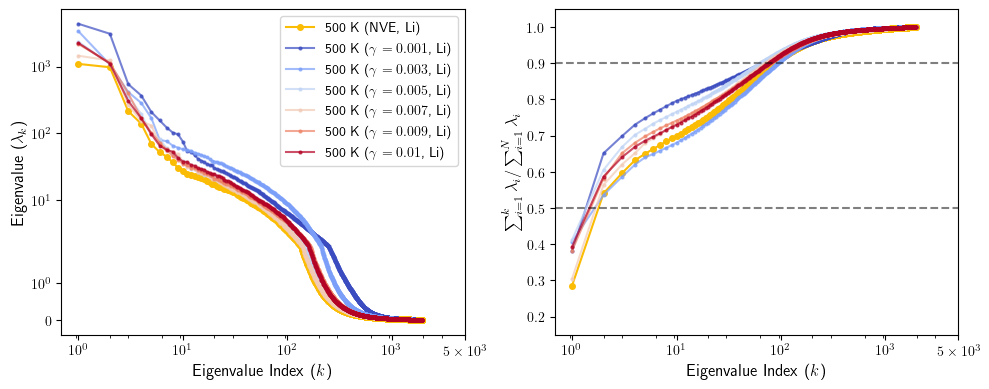

In [8]:
element = "Li"
input_atom_order = read("/Volumes/Expansion/Jack_work_data/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/CONTCAR").get_chemical_symbols()
element_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == element]
element_indices = list(np.array([[3 * i, 3 * i + 1, 3 * i + 2] for i in element_indices]).reshape(-1))


covariance_matrix_element = covariance_matrix[np.ix_(element_indices, element_indices)]
covariance_matrix_lambda_0_001_element = covariance_matrix_lambda_0_001[np.ix_(element_indices, element_indices)]
covariance_matrix_lambda_0_003_element = covariance_matrix_lambda_0_003[np.ix_(element_indices, element_indices)]
covariance_matrix_lambda_0_005_element = covariance_matrix_lambda_0_005[np.ix_(element_indices, element_indices)]
covariance_matrix_lambda_0_007_element = covariance_matrix_lambda_0_007[np.ix_(element_indices, element_indices)]
covariance_matrix_lambda_0_009_element = covariance_matrix_lambda_0_009[np.ix_(element_indices, element_indices)]
covariance_matrix_lambda_0_01_element = covariance_matrix_lambda_0_01[np.ix_(element_indices, element_indices)]

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
eigenvalues_lambda_0_001, eigenvectors_lambda_0_001 = np.linalg.eigh(covariance_matrix_lambda_0_001)
eigenvalues_lambda_0_003, eigenvectors_lambda_0_003 = np.linalg.eigh(covariance_matrix_lambda_0_003)
eigenvalues_lambda_0_005, eigenvectors_lambda_0_005 = np.linalg.eigh(covariance_matrix_lambda_0_005)
eigenvalues_lambda_0_007, eigenvectors_lambda_0_007 = np.linalg.eigh(covariance_matrix_lambda_0_007)
eigenvalues_lambda_0_009, eigenvectors_lambda_0_009 = np.linalg.eigh(covariance_matrix_lambda_0_009)
eigenvalues_lambda_0_01, eigenvectors_lambda_0_01 = np.linalg.eigh(covariance_matrix_lambda_0_01)

eigenvalues_element, eigenvectors_element = np.linalg.eigh(covariance_matrix_element)
eigenvalues_lambda_0_001_element, eigenvectors_lambda_0_001_element = np.linalg.eigh(covariance_matrix_lambda_0_001_element)
eigenvalues_lambda_0_003_element, eigenvectors_lambda_0_003_element = np.linalg.eigh(covariance_matrix_lambda_0_003_element)
eigenvalues_lambda_0_005_element, eigenvectors_lambda_0_005_element = np.linalg.eigh(covariance_matrix_lambda_0_005_element)
eigenvalues_lambda_0_007_element, eigenvectors_lambda_0_007_element = np.linalg.eigh(covariance_matrix_lambda_0_007_element)
eigenvalues_lambda_0_009_element, eigenvectors_lambda_0_009_element = np.linalg.eigh(covariance_matrix_lambda_0_009_element)
eigenvalues_lambda_0_01_element, eigenvectors_lambda_0_01_element = np.linalg.eigh(covariance_matrix_lambda_0_01_element)

eigenvalues = eigenvalues[np.argsort(eigenvalues)[::-1]]
eigenvalues_lambda_0_001 = eigenvalues_lambda_0_001[np.argsort(eigenvalues_lambda_0_001)[::-1]]
eigenvalues_lambda_0_003 = eigenvalues_lambda_0_003[np.argsort(eigenvalues_lambda_0_003)[::-1]]
eigenvalues_lambda_0_005 = eigenvalues_lambda_0_005[np.argsort(eigenvalues_lambda_0_005)[::-1]]
eigenvalues_lambda_0_007 = eigenvalues_lambda_0_007[np.argsort(eigenvalues_lambda_0_007)[::-1]]
eigenvalues_lambda_0_009 = eigenvalues_lambda_0_009[np.argsort(eigenvalues_lambda_0_009)[::-1]]
eigenvalues_lambda_0_01 = eigenvalues_lambda_0_01[np.argsort(eigenvalues_lambda_0_01)[::-1]]

eigenvalues_element = eigenvalues_element[np.argsort(eigenvalues_element)[::-1]]
eigenvalues_lambda_0_001_element = eigenvalues_lambda_0_001_element[np.argsort(eigenvalues_lambda_0_001_element)[::-1]]
eigenvalues_lambda_0_003_element = eigenvalues_lambda_0_003_element[np.argsort(eigenvalues_lambda_0_003_element)[::-1]]
eigenvalues_lambda_0_005_element = eigenvalues_lambda_0_005_element[np.argsort(eigenvalues_lambda_0_005_element)[::-1]]
eigenvalues_lambda_0_007_element = eigenvalues_lambda_0_007_element[np.argsort(eigenvalues_lambda_0_007_element)[::-1]]
eigenvalues_lambda_0_009_element = eigenvalues_lambda_0_009_element[np.argsort(eigenvalues_lambda_0_009_element)[::-1]]
eigenvalues_lambda_0_01_element = eigenvalues_lambda_0_01_element[np.argsort(eigenvalues_lambda_0_01_element)[::-1]]

colors = plt.cm.coolwarm(np.linspace(0, 1, 6))
color = 'r'
color_lambda_0_001 = colors[0]
color_lambda_0_003 = colors[1]
color_lambda_0_005 = colors[2]
color_lambda_0_007 = colors[3]
color_lambda_0_009 = colors[4]
color_lambda_0_01 = colors[5]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot([i + 1 for i in range(len(eigenvalues_element))], eigenvalues_element, "o-", c="#FBBC05", label="500 K (NVE, Li)", alpha=1, markersize=4)

ax[0].plot([i + 1 for i in range(len(eigenvalues_lambda_0_001_element))], eigenvalues_lambda_0_001_element, "o-", label="500 K ($\\gamma=0.001$, Li)", c=color_lambda_0_001, alpha=0.7,markersize=2)
ax[0].plot([i + 1 for i in range(len(eigenvalues_lambda_0_003_element))], eigenvalues_lambda_0_003_element, "o-", label="500 K ($\\gamma=0.003$, Li)", c=color_lambda_0_003, alpha=0.7,markersize=2)
ax[0].plot([i + 1 for i in range(len(eigenvalues_lambda_0_005_element))], eigenvalues_lambda_0_005_element, "o-", label="500 K ($\\gamma=0.005$, Li)", c=color_lambda_0_005, alpha=0.7,markersize=2)
ax[0].plot([i + 1 for i in range(len(eigenvalues_lambda_0_007_element))], eigenvalues_lambda_0_007_element, "o-", label="500 K ($\\gamma=0.007$, Li)", c=color_lambda_0_007, alpha=0.7,markersize=2)
ax[0].plot([i + 1 for i in range(len(eigenvalues_lambda_0_009_element))], eigenvalues_lambda_0_009_element, "o-", label="500 K ($\\gamma=0.009$, Li)", c=color_lambda_0_009, alpha=0.7,markersize=2)
ax[0].plot([i + 1 for i in range(len(eigenvalues_lambda_0_01_element))], eigenvalues_lambda_0_01_element, "o-", label="500 K ($\\gamma=0.01$, Li)", c=color_lambda_0_01, alpha=0.7,markersize=2)


ax[0].set_yscale("symlog")
# ax[0].set_ylim(5e-2, 5e3)
ax[0].set_xscale("log", base=np.sqrt(10))
ax[0].set_xticks([1, 10, 100, 1000, 5000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$5\\times10^3$"])
ax[0].set_xlabel("Eigenvalue Index ($k$)", fontsize=12)
ax[0].set_ylabel("Eigenvalue ($\\lambda_k$)", fontsize=12)
ax[0].tick_params(axis="both", which="both", labelsize=10)
ax[0].legend(fontsize=10)

ax[1].plot([i + 1 for i in range(len(eigenvalues_element))],[np.sum(eigenvalues_element[: i + 1]) / np.sum(eigenvalues_element) for i in range(len(eigenvalues_element))],"o-",c='#FBBC05',alpha=1,markersize=4)
ax[1].plot([i + 1 for i in range(len(eigenvalues_lambda_0_001_element))],[np.sum(eigenvalues_lambda_0_001_element[: i + 1]) / np.sum(eigenvalues_lambda_0_001_element) for i in range(len(eigenvalues_lambda_0_001_element))],"o-",c=color_lambda_0_001,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_lambda_0_003_element))],[np.sum(eigenvalues_lambda_0_003_element[: i + 1]) / np.sum(eigenvalues_lambda_0_003_element) for i in range(len(eigenvalues_lambda_0_003_element))],"o-",c=color_lambda_0_003,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_lambda_0_005_element))],[np.sum(eigenvalues_lambda_0_005_element[: i + 1]) / np.sum(eigenvalues_lambda_0_005_element) for i in range(len(eigenvalues_lambda_0_005_element))],"o-",c=color_lambda_0_005,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_lambda_0_007_element))],[np.sum(eigenvalues_lambda_0_007_element[: i + 1]) / np.sum(eigenvalues_lambda_0_007_element) for i in range(len(eigenvalues_lambda_0_007_element))],"o-",c=color_lambda_0_007,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_lambda_0_009_element))],[np.sum(eigenvalues_lambda_0_009_element[: i + 1]) / np.sum(eigenvalues_lambda_0_009_element) for i in range(len(eigenvalues_lambda_0_009_element))],"o-",c=color_lambda_0_009,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_lambda_0_01_element))],[np.sum(eigenvalues_lambda_0_01_element[: i + 1]) / np.sum(eigenvalues_lambda_0_01_element) for i in range(len(eigenvalues_lambda_0_01_element))],"o-",c=color_lambda_0_01,alpha=0.7,markersize=2)

ax[1].set_xscale("log", base=np.sqrt(10))
ax[1].set_xticks([1, 10, 100, 1000, 5000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$5\\times10^3$"])
ax[1].set_xlabel("Eigenvalue Index ($k$)", fontsize=12)
ax[1].set_ylabel("$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$", fontsize=12)
ax[1].tick_params(axis="both", which="both", labelsize=10)
ax[1].axhline(0.9, c="k", ls="--", alpha=0.5)
ax[1].axhline(0.5, c="k", ls="--", alpha=0.5)
ax[1].set_ylim(0.15,1.05)
plt.tight_layout()
plt.savefig("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion-documents/langevin_md_essential_dynamics_analysis_600K.pdf")

plt.show()